# 5. Read the metrics and test your own matrices

What every number means, when a case is `ok`, how to build test matrices that stress your
method, how to save results, and what the GPU check adds. Text version:
[tutorial 5](../docs/tutorials/05-metrics-and-matrices.md). About a minute on a CPU.

In [1]:
# Setup: find the repository, choose the device. Run this cell first.
from pathlib import Path
import os, sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'svdlab' / '__init__.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))      # works even if the package is not installed with pip
os.chdir(ROOT)                         # all paths below are relative to the repository root

import torch
import svdlab

USE_GPU = True                         # set to False to stay on the CPU even when a GPU is present
DEVICE = 'cuda' if USE_GPU and torch.cuda.is_available() else 'cpu'
torch.set_num_threads(4)
print(f'torch {torch.__version__}, device: {DEVICE}' + (f' ({torch.cuda.get_device_name(0)})' if DEVICE == 'cuda' else ''))

torch 2.14.1+cu130, device: cpu


## The metrics, recomputed by hand

`svdlab` compares your result with a reference SVD of the exact input, computed with
LAPACK in float64. Below, the main metrics are recomputed with NumPy for one case, to show
there is nothing hidden.

In [2]:
import numpy as np
from svdlab import MatrixCase

case = MatrixCase.create(m=48, n=32, family='gaussian', dtype='float64')
A = case.array                                     # the exact input, as NumPy
U, s, Vh = (x.cpu().numpy() for x in torch.linalg.svd(case.tensor(DEVICE), full_matrices=False))
s_ref = case.reference[0][1]                        # reference singular values
k = len(s)

recon = np.linalg.norm(A - (U * s) @ Vh) / np.linalg.norm(A)
orth_u = np.linalg.norm(U.conj().T @ U - np.eye(k)) / np.sqrt(k)
orth_v = np.linalg.norm(Vh @ Vh.conj().T - np.eye(k)) / np.sqrt(k)
sigma_rel = np.max(np.abs(s - s_ref) / s_ref)
tol = 100 * np.finfo(A.dtype).eps * max(A.shape)
print(f'recon {recon:.2e}  orth_u {orth_u:.2e}  orth_v {orth_v:.2e}  σ-rel {sigma_rel:.2e}  tol {tol:.1e}')

row = svdlab.check('torch', [case], device=DEVICE, verbose=False)[0]
print(f"svdlab: recon {row['reconstruction_relative_fro']:.2e}  orth_u {row['orthogonality_u_fro_over_sqrt_cols']:.2e}  "
      f"orth_v {row['orthogonality_v_fro_over_sqrt_rows']:.2e}  σ-rel {row['resolved_spectrum_max_relative_error']:.2e}  ok {row['ok']}")

recon 1.55e-15  orth_u 1.23e-15  orth_v 1.23e-15  σ-rel 1.78e-15  tol 1.1e-12
svdlab: recon 1.55e-15  orth_u 1.23e-15  orth_v 1.23e-15  σ-rel 1.78e-15  ok True


## When a case is `ok`

`tol = 100 · eps(dtype) · max(m, n)`, so the bar depends on precision and size:

In [3]:
for dtype, (m, n) in [('float64', (48, 32)), ('float64', (400, 300)), ('float32', (400, 300))]:
    print(f'{dtype:<8} {m}x{n}: tol = {100 * np.finfo(dtype).eps * max(m, n):.1e}')

float64  48x32: tol = 1.1e-12
float64  400x300: tol = 8.9e-12
float32  400x300: tol = 4.8e-03


| Case type | `ok` when |
| --- | --- |
| full SVD (`rank == min(m, n)`) | `s` sorted and ≥ 0, both orthogonality errors ≤ tol, `recon` ≤ tol |
| truncated (`rank < min(m, n)`) | `s` sorted and ≥ 0, both orthogonality errors ≤ tol, `tail×` ≤ 1.05 |
| only `s` returned | `s` sorted and ≥ 0, max \|s − σ\| / σ₁ ≤ tol |

### A truncated case is judged by its residual

`tail×` is the residual divided by the best possible rank-k residual (Eckart–Young).
Randomized SVD with rank 5 is `ok` on both matrices below, but its singular values are
accurate only when the spectrum decays. If your application needs the values, look at
`σ-rel` too.

In [4]:
cases = [dict(name='gaussian_rank5', m=60, n=40, family='gaussian', output_rank=5),
         dict(name='low_rank_rank5', m=60, n=40, family='low_rank', rank=5, tail=1e-8, output_rank=5)]
rows = svdlab.check('randomized', cases, device=DEVICE)

randomized           gaussian_rank5         ok      32.931 ms  recon 8.28e-01  tail× 1.00e+00  σ-rel 1.38e-02  orth 2.98e-15


randomized           low_rank_rank5         ok      25.625 ms  recon 4.90e-08  tail× 1.00e+00  σ-rel 1.40e-15  orth 8.46e-16


### Only singular values

A method that returns a single 1-D tensor is checked on its values alone; `recon` and `orth`
are then `-`.

In [5]:
rows = svdlab.check(lambda a, rank: torch.linalg.svdvals(a), svdlab.QUICK_SUITE, name='svdvals', device=DEVICE)

svdvals              gaussian_tall          ok       0.107 ms  recon -  tail× -  σ-rel 1.78e-15  orth 0.00e+00
svdvals              gaussian_wide          ok       0.042 ms  recon -  tail× -  σ-rel 2.16e-15  orth 0.00e+00


svdvals              ill_conditioned_1e8    ok       0.046 ms  recon -  tail× -  σ-rel 2.10e-10  orth 0.00e+00
svdvals              clustered              ok       0.064 ms  recon -  tail× -  σ-rel 2.19e-14  orth 0.00e+00


svdvals              complex_gaussian       ok       0.045 ms  recon -  tail× -  σ-rel 1.75e-15  orth 0.00e+00
svdvals              low_rank_k4            ok       0.267 ms  recon -  tail× -  σ-rel 2.78e-16  orth 0.00e+00


## Your own matrices

A case is a dict of generator arguments or a `MatrixCase`. Families: `gaussian`,
`geometric` (`condition`), `clustered` (`cluster_size`, `cluster_spread`, `condition`),
`low_rank` (`rank`, `tail`), `sparse` (`density`), `zero`. Common arguments: `m`, `n`,
`dtype`, `seed`, `name`, and `output_rank` (the `rank` passed to the method; default: full).
`MatrixCase.from_spectrum([...])` gives exactly the singular values you choose and
`MatrixCase.load('file.npy')` loads your own data.

In [6]:
my_cases = [
    dict(name='tall_fp32', m=500, n=200, family='gaussian', dtype='float32'),
    dict(name='cond_1e12', m=200, n=200, family='geometric', condition=1e12),
    dict(name='pairs', m=120, n=80, family='clustered', cluster_size=2, cluster_spread=1e-10),
    dict(name='rank20', m=800, n=400, family='low_rank', rank=20, tail=1e-6, output_rank=20),
    MatrixCase.from_spectrum([5, 5, 1, 1e-3, 1e-9, 0], m=10, n=8),     # repeated and zero values
]
# Save a matrix and load it back, as you would with your own data:
Path('laboratory_runs').mkdir(exist_ok=True)
np.save('laboratory_runs/example_matrix.npy', np.random.default_rng(0).standard_normal((64, 48)))
loaded = MatrixCase.load('laboratory_runs/example_matrix.npy')
loaded.spec['name'] = 'my_matrix'                  # the name shown in the report
my_cases.append(loaded)

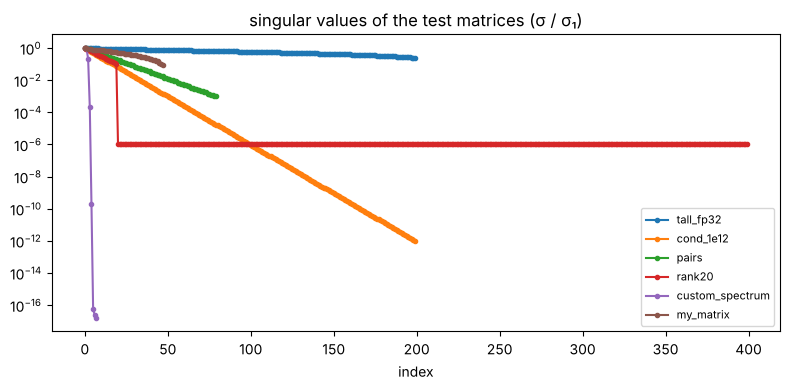

In [7]:
import matplotlib.pyplot as plt
from svdlab.scorecard import make_case

fig, ax = plt.subplots(figsize=(8, 4))
for spec in my_cases:
    name, mc, _ = make_case(spec)
    ax.semilogy(mc.reference[0][1] / mc.reference[0][1][0], '.-', label=name)
ax.set_title('singular values of the test matrices (σ / σ₁)'); ax.set_xlabel('index'); ax.legend(fontsize=8)
plt.tight_layout()

Run two methods on them: the library SVD and the Gram-matrix SVD from notebook 2
(`examples/gram_svd.py`), which squares the condition number:

In [8]:
import warnings
with warnings.catch_warnings():
    # gram_svd divides by singular values that are exactly zero here (from_spectrum, cond_1e12),
    # so its U overflows; the check reports that as orth = inf instead of crashing.
    warnings.simplefilter('ignore', RuntimeWarning)
    rows = svdlab.compare({'torch': 'torch', 'gram_svd': 'examples/gram_svd.py'}, my_cases, device=DEVICE, repeat=3)

torch                tall_fp32              ok       6.044 ms  recon 1.46e-06  tail× -  σ-rel 1.02e-06  orth 1.22e-06


torch                cond_1e12              ok       4.316 ms  recon 1.88e-15  tail× -  σ-rel 1.79e-05  orth 1.72e-15


torch                pairs                  ok       4.797 ms  recon 2.20e-15  tail× -  σ-rel 1.89e-14  orth 1.70e-15


torch                rank20                 ok      24.227 ms  recon 9.08e-06  tail× 1.00e+00  σ-rel 2.16e-15  orth 1.44e-15
torch                custom_spectrum        ok       0.035 ms  recon 8.98e-16  tail× -  σ-rel 7.78e-08  orth 6.60e-16


torch                my_matrix              ok       0.543 ms  recon 1.92e-15  tail× -  σ-rel 3.35e-15  orth 1.57e-15


gram_svd             tall_fp32              ok       2.501 ms  recon 1.09e-06  tail× -  σ-rel 5.27e-07  orth 1.69e-06


gram_svd             cond_1e12              FAIL     2.217 ms  recon 7.48e-09  tail× -  σ-rel 1.48e+01  orth inf


gram_svd             pairs                  FAIL     0.643 ms  recon 1.86e-15  tail× -  σ-rel 3.84e-11  orth 4.04e-11


gram_svd             rank20                 ok      12.841 ms  recon 9.08e-06  tail× 1.00e+00  σ-rel 1.98e-15  orth 2.00e-15
gram_svd             custom_spectrum        FAIL     0.054 ms  recon 1.40e-10  tail× -  σ-rel 5.46e+01  orth inf


gram_svd             my_matrix              ok       0.255 ms  recon 1.90e-15  tail× -  σ-rel 3.92e-15  orth 4.26e-15


## Save and analyze

`save` writes CSV (or JSON for a `.json` name) with every column; `table` gives a pandas
DataFrame. Terminal equivalent: `--csv results.csv`.

In [9]:
path = svdlab.save(rows, 'laboratory_runs/tutorial5.csv')
print('saved', path)
df = svdlab.table(rows)
df.pivot(index='case', columns='method', values='orthogonality_u_fro_over_sqrt_cols').map('{:.1e}'.format)

saved laboratory_runs/tutorial5.csv


method,gram_svd,torch
case,,
cond_1e12,inf,1.7e-15
custom_spectrum,inf,6.6e-16
my_matrix,4.3e-15,1.4e-15
pairs,4.0e-11,1.7e-15
rank20,2.0e-15,1.4e-15
tall_fp32,1.7e-06,1.2e-06


In [10]:
print('All columns:', ', '.join(df.columns))

All columns: method, case, m, n, dtype, rank, device, output_device, status, ok, time_median_ms, time_mad_ms, device_time_median_ms, gpu_peak_increment_bytes, reconstruction_relative_fro, residual_over_optimal_tail, resolved_spectrum_max_relative_error, spectrum_error_over_sigma1, orthogonality_u_fro_over_sqrt_cols, orthogonality_v_fro_over_sqrt_rows, left_triplet_relative_fro, right_triplet_relative_fro, right_subspace_leakage_fro_over_sqrt_k, singular_values_nonnegative_sorted, error, reference_tail_relative_fro


## The GPU check

`gpu_check` runs the method on the CPU and on the GPU. `passed` requires: result returned
on the GPU (`on_gpu`), `ok` on both devices, and singular values that agree within the
tolerance. It catches code that silently computes on the host and GPU paths that are
numerically different. Skipped on a CPU-only machine.

In [11]:
if DEVICE == 'cuda':
    def host_fallback(a, rank):                     # deliberately wrong: computes on the CPU
        return torch.linalg.svd(a.cpu(), full_matrices=False)
    for method in ('torch', host_fallback):
        gpu_rows = svdlab.gpu_check(method, svdlab.QUICK_SUITE, verbose=False)
        display(svdlab.table(gpu_rows)[['method', 'case', 'passed', 'cpu_ok', 'gpu_ok', 'output_device', 'on_gpu',
                                        'max_singular_value_difference_over_sigma1', 'speedup']])
else:
    print('No CUDA/ROCm device visible to torch: GPU check skipped.')

No CUDA/ROCm device visible to torch: GPU check skipped.


## Next

- [Developer guide](../docs/DEVELOPER_GUIDE.md): every option and block in one page.
- [Algorithm laboratory](../docs/ALGORITHM_LABORATORY.md): look inside an algorithm while it runs.